# Elastic Net Midterm 1: Expanding Window, Yearly Hyperparameter + Coefficient Freeze

Aligned to GARCH / GARCH-MIDAS's re-estimation cadence: since GARCH can only
be re-estimated once a year, Elastic Net's hyperparameter search (5-fold CV
for `alpha`/`l1_ratio`) **and** coefficient fit both happen together once
every 12 months and are frozen in between -- only the monthly input `X_t`
(macro values + own-lag, all actually known/realized at time t) changes
between refits, never the fitted relationship itself. This keeps the MSE
comparison against GARCH fair: neither model gets to adapt more often than
the other.

Primary experiment: **expanding window** (each yearly refit trains on all
history since month 0). Side experiment at the bottom: **rolling window**
(each yearly refit trains on only the most recent 60 months).

# What this notebook does

Elastic Net forecasting log(RV²) one month ahead for 5 cyclical sector ETFs
(XLI, XLB, XLE, XLY, XLF), using macro variables + the ETF's own lagged RV²
as features.

**Data:** macro predictors (already vintage-lag corrected, using Sarahs) joined with RV²
built from CRSP daily returns -> monthly RV² -> log. X at month t (macro +
own RV² at t, both known by end of month t) predicts y at month t = log(RV²)
realized in month t+1.

**Walk-forward setup:** starts forecasting after 60 months of burn-in.
Every 12 months, refits both the hyperparameters (5-fold time series CV over alpha/
l1_ratio) and the coefficients on all data up to that point, then freezes
that fitted model and just predicts on each new month's real macro/lag
values for the next 12 months, until the next refit. This 12-month freeze
matches GARCH-MIDAS's yearly re-estimation cadence.

**Two versions run:**
1. Expanding window (main) — each yearly refit trains on all history since
   month 0 (grows over time).
2. Rolling window (side test) — each yearly refit trains on only the most
   recent 60 months instead.
- Result is that expanding window performs better than rolling window
**Evaluation:** for each ticker, computes MSE/RMSE/MAE plus R²_OOS against
two baselines — an expanding historical mean, and a persistence (naive
"next month = this month") forecast — to check whether the model is adding
real predictive value over doing nothing. For midterm, just focus on MSE and ignore the rest.

**Results:** expanding window beats rolling window on every ticker. Against
persistence specifically, expanding wins on 4/5 tickers (XLE is the
exception — negative R²_OOS vs persistence in both expanding and rolling).

In [10]:
import os
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.exceptions import ConvergenceWarning

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

PROJECT_ROOT = "../.."
CYCLICAL_TICKERS = ["XLI", "XLB", "XLE", "XLY", "XLF"]

MACRO_PATH = os.path.join(PROJECT_ROOT, "dataset", "macro_variables", "final_clean", "final_macro_data.csv")
PRICE_PATH = os.path.join(PROJECT_ROOT, "dataset", "price", "clean", "daily_returns_panel.csv")
FORECASTS_DIR = os.path.join(PROJECT_ROOT, "dataset", "forecasts")

BURN_IN = 60        # months of history required before the first fit/forecast
REFIT_EVERY = 12    # months between hyperparameter search + coefficient refits
L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]

## Data

Macro predictors from `final_macro_data.csv` -- already vintage/publication-lag
corrected and transformed (levels vs. log-diff per channel), no re-derivation
needed here. Target built the same way as the expanding-window notebook: CRSP
`DlyRet` (raw sector returns, `ret_*` columns) -> monthly RV² (sum of squared
daily returns) -> `log(RV²)`, aligned so `X.loc[t]` (known at month t) pairs
with `y.loc[t] = log(RV²)` realized in month t+1.

In [ ]:
macro = pd.read_csv(MACRO_PATH, index_col="date", parse_dates=True)
FINAL_MACRO_VARS = [col for col in macro.columns if col != "NBUSBIS"]
macro = macro[FINAL_MACRO_VARS].copy()
print(f"{len(FINAL_MACRO_VARS)} macro variables (vintage/publication-lag corrected):", FINAL_MACRO_VARS)
print(f"macro range: {macro.index.min().date()} to {macro.index.max().date()}\n")

price = pd.read_csv(PRICE_PATH, index_col="date", parse_dates=True)
ret_cols = {ticker: f"ret_{ticker}" for ticker in CYCLICAL_TICKERS}
daily_returns = price[list(ret_cols.values())].rename(columns={v: k for k, v in ret_cols.items()})

monthly_rv_squared = daily_returns.pow(2).resample("ME").sum()
log_rv_squared = np.log(monthly_rv_squared)
print("log_rv_squared:", log_rv_squared.index.min().date(), "to", log_rv_squared.index.max().date(),
      f"({len(log_rv_squared)} months)")

aligned_data = {}
for ticker in CYCLICAL_TICKERS:
    own_lag = log_rv_squared[ticker].rename("own_log_rv_sq_lag0")
    y = log_rv_squared[ticker].shift(-1)
    y.name = "y_log_rv_squared_tplus1"
    df = macro.join(own_lag, how="inner").join(y, how="inner").dropna()
    aligned_data[ticker] = df
    print(f"{ticker}: {df.shape[0]} aligned rows, {df.index.min().date()} to {df.index.max().date()}")

ALL_FEATURE_COLS = FINAL_MACRO_VARS + ["own_log_rv_sq_lag0"]
print()
print(f"{len(ALL_FEATURE_COLS)} features per model:", ALL_FEATURE_COLS)

## Walk-forward validation — EXPANDING window, yearly freeze

At month `BURN_IN` (60), fit on months `0:60` -- 5-fold `TimeSeriesSplit` CV
picks `alpha`/`l1_ratio`, then final coefficients are fit -- and use that
frozen pipeline to predict months `60:72`. At month 72, refit on `0:72`
(hyperparameters + coefficients both re-estimated), predict `72:84`. Repeat.
Training window grows by `REFIT_EVERY` months at each cycle; the model itself
only changes at cycle boundaries -- exactly matching GARCH's yearly
re-estimation cadence, while still producing a fresh forecast every month
(since the real, realized `X_t` changes monthly even though the coefficients
don't).

In [12]:
def walk_forward_expanding_yearly(df, feature_cols, burn_in=BURN_IN, refit_every=REFIT_EVERY, l1_ratios=L1_RATIOS):
    """Expanding window, yearly freeze: at each `refit_every`-month cycle, run
    ElasticNetCV (5-fold TimeSeriesSplit) + final fit on ALL data from month 0
    up to that point -- both hyperparameters and coefficients frozen for the
    next `refit_every` months, matching GARCH/GARCH-MIDAS's yearly
    re-estimation cadence. Between refits, the frozen pipeline is only used to
    predict -- never refit -- on each new month's real, realized X_t."""
    X = df[feature_cols].to_numpy()
    y = df["y_log_rv_squared_tplus1"].to_numpy()
    dates = df.index
    n = len(df)
    rows = []
    pipe = None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=ConvergenceWarning)
        for i in range(burn_in, n):
            refit_this_month = (i - burn_in) % refit_every == 0
            if refit_this_month:
                pipe = Pipeline([
                    ("scaler", StandardScaler()),
                    ("enet", ElasticNetCV(
                        l1_ratio=l1_ratios,
                        cv=TimeSeriesSplit(n_splits=5),
                        max_iter=10000,
                        random_state=0,
                    )),
                ])
                pipe.fit(X[:i], y[:i])
            pred = pipe.predict(X[i:i + 1])[0]
            enet = pipe.named_steps["enet"]
            rows.append({
                "date": dates[i],
                "log_rv_sq_actual": y[i],
                "log_rv_sq_pred": pred,
                "alpha": enet.alpha_,
                "l1_ratio": enet.l1_ratio_,
                "refit_this_month": refit_this_month,
                "train_months": i,
            })
    return pd.DataFrame(rows).set_index("date")

In [13]:
t0 = time.time()
forecasts_expanding = {}
for ticker in CYCLICAL_TICKERS:
    t1 = time.time()
    forecasts_expanding[ticker] = walk_forward_expanding_yearly(aligned_data[ticker], ALL_FEATURE_COLS)
    print(f"{ticker}: {len(forecasts_expanding[ticker])} forecasts, {time.time() - t1:.1f}s")
print(f"total: {time.time() - t0:.1f}s")

os.makedirs(FORECASTS_DIR, exist_ok=True)
for ticker, df in forecasts_expanding.items():
    out = df.copy()
    out["rv2_hat"] = np.exp(out["log_rv_sq_pred"])
    out["rv2_actual"] = np.exp(out["log_rv_sq_actual"])
    out_path = os.path.join(FORECASTS_DIR, f"elastic_net_expanding_yearly_{ticker}.csv")
    out.to_csv(out_path)
    forecasts_expanding[ticker] = out
    print(f"Saved {out_path} ({len(out)} rows)")

XLI: 215 forecasts, 2.7s
XLB: 215 forecasts, 2.8s
XLE: 215 forecasts, 2.6s
XLY: 215 forecasts, 2.4s
XLF: 215 forecasts, 2.5s
total: 13.0s
Saved ../../dataset/forecasts/elastic_net_expanding_yearly_XLI.csv (215 rows)
Saved ../../dataset/forecasts/elastic_net_expanding_yearly_XLB.csv (215 rows)
Saved ../../dataset/forecasts/elastic_net_expanding_yearly_XLE.csv (215 rows)
Saved ../../dataset/forecasts/elastic_net_expanding_yearly_XLY.csv (215 rows)
Saved ../../dataset/forecasts/elastic_net_expanding_yearly_XLF.csv (215 rows)


## Accuracy

For **midterm**, can just focus on MSE under the accuracy table: **"=== Expanding window (yearly freeze): accuracy ==="**
Can ignore the "expanding window vs persistence baseline comparison" 

MSE/RMSE/MAE + out-of-sample R² vs. a leak-free expanding historical-mean
benchmark, plus a persistence-baseline comparison (both computed the same way
as the expanding-window notebook, not sklearn's `r2_score` directly).

In [14]:
def historical_mean_benchmark(aligned_df, start_idx):
    y_full = aligned_df["y_log_rv_squared_tplus1"]
    n = len(y_full)
    benchmark = [y_full.iloc[:i].mean() for i in range(start_idx, n)]
    return pd.Series(benchmark, index=y_full.index[start_idx:n])


def accuracy_table(forecasts, aligned, start_idx, label):
    rows, persistence_rows = [], []
    for ticker in CYCLICAL_TICKERS:
        df = forecasts[ticker]
        actual = df["log_rv_sq_actual"]
        pred = df["log_rv_sq_pred"]

        benchmark = historical_mean_benchmark(aligned[ticker], start_idx).reindex(df.index)
        resid = actual - pred
        mse = (resid ** 2).mean()
        r2_oos = 1 - (resid ** 2).sum() / ((actual - benchmark) ** 2).sum()
        rows.append({
            "ticker": ticker, "n_forecasts": len(df),
            "MSE": mse, "RMSE": np.sqrt(mse), "MAE": resid.abs().mean(), "R2_OOS": r2_oos,
        })

        persistence_pred = actual.shift(1)
        valid = persistence_pred.notna()
        resid_model = (actual - pred)[valid]
        resid_naive = (actual - persistence_pred)[valid]
        r2_vs_persistence = 1 - (resid_model ** 2).sum() / (resid_naive ** 2).sum()
        persistence_rows.append({
            "ticker": ticker,
            "MSE_model": (resid_model ** 2).mean(),
            "MSE_persistence": (resid_naive ** 2).mean(),
            "R2_OOS_vs_persistence": r2_vs_persistence,
        })

    acc_df = pd.DataFrame(rows).set_index("ticker")
    pers_df = pd.DataFrame(persistence_rows).set_index("ticker")
    print(f"=== {label}: accuracy ===")
    print(acc_df)
    print()
    print(f"=== {label}: vs persistence baseline ===")
    print(pers_df)
    return acc_df, pers_df


accuracy_expanding_df, persistence_expanding_df = accuracy_table(
    forecasts_expanding, aligned_data, BURN_IN, "Expanding window (yearly freeze)"
)

=== Expanding window (yearly freeze): accuracy ===
        n_forecasts       MSE      RMSE       MAE    R2_OOS
ticker                                                     
XLI             215  0.421143  0.648955  0.472090  0.534462
XLB             215  0.404063  0.635660  0.470579  0.516739
XLE             215  0.679517  0.824328  0.559277  0.276718
XLY             215  0.473808  0.688337  0.537994  0.547931
XLF             215  0.642829  0.801766  0.600367  0.532441

=== Expanding window (yearly freeze): vs persistence baseline ===
        MSE_model  MSE_persistence  R2_OOS_vs_persistence
ticker                                                   
XLI      0.423102         0.629692               0.328082
XLB      0.405815         0.541119               0.250045
XLE      0.679313         0.510374              -0.331011
XLY      0.476011         0.574806               0.171875
XLF      0.645832         0.729923               0.115205


## Side experiment — ROLLING window (60mo), same yearly freeze

Identical mechanics to the expanding version above -- hyperparameters and
coefficients both frozen for `REFIT_EVERY` months at a time -- except each
refit trains on only the most recent `window` (60) months (`X[i-window:i]`)
instead of everything since month 0. Tests whether a fixed-size lookback
beats a growing one.

In [15]:
def walk_forward_rolling_yearly(df, feature_cols, window=BURN_IN, refit_every=REFIT_EVERY, l1_ratios=L1_RATIOS):
    """Same yearly-freeze mechanics as walk_forward_expanding_yearly, except
    each refit trains on only the most recent `window` months (X[i-window:i])
    instead of everything since month 0."""
    X = df[feature_cols].to_numpy()
    y = df["y_log_rv_squared_tplus1"].to_numpy()
    dates = df.index
    n = len(df)
    rows = []
    pipe = None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=ConvergenceWarning)
        for i in range(window, n):
            refit_this_month = (i - window) % refit_every == 0
            if refit_this_month:
                train_start = i - window
                pipe = Pipeline([
                    ("scaler", StandardScaler()),
                    ("enet", ElasticNetCV(
                        l1_ratio=l1_ratios,
                        cv=TimeSeriesSplit(n_splits=5),
                        max_iter=10000,
                        random_state=0,
                    )),
                ])
                pipe.fit(X[train_start:i], y[train_start:i])
            pred = pipe.predict(X[i:i + 1])[0]
            enet = pipe.named_steps["enet"]
            rows.append({
                "date": dates[i],
                "log_rv_sq_actual": y[i],
                "log_rv_sq_pred": pred,
                "alpha": enet.alpha_,
                "l1_ratio": enet.l1_ratio_,
                "refit_this_month": refit_this_month,
            })
    return pd.DataFrame(rows).set_index("date")

Changed the dataset/forecasts directory to forecasts, ignore this notebook or change the directory below if you want to save it to the correct place

In [16]:
t0 = time.time()
forecasts_rolling = {}
for ticker in CYCLICAL_TICKERS:
    t1 = time.time()
    forecasts_rolling[ticker] = walk_forward_rolling_yearly(aligned_data[ticker], ALL_FEATURE_COLS)
    print(f"{ticker}: {len(forecasts_rolling[ticker])} forecasts, {time.time() - t1:.1f}s")
print(f"total: {time.time() - t0:.1f}s")

for ticker, df in forecasts_rolling.items():
    out = df.copy()
    out["rv2_hat"] = np.exp(out["log_rv_sq_pred"])
    out["rv2_actual"] = np.exp(out["log_rv_sq_actual"])
    out_path = os.path.join(FORECASTS_DIR, f"elastic_net_rolling_yearly_{ticker}.csv")
    out.to_csv(out_path)
    forecasts_rolling[ticker] = out
    print(f"Saved {out_path} ({len(out)} rows)")

accuracy_rolling_df, persistence_rolling_df = accuracy_table(
    forecasts_rolling, aligned_data, BURN_IN, "Rolling window (60mo, yearly freeze)"
)

XLI: 215 forecasts, 2.8s
XLB: 215 forecasts, 6.7s
XLE: 215 forecasts, 4.2s
XLY: 215 forecasts, 2.7s
XLF: 215 forecasts, 5.3s
total: 21.7s
Saved ../../dataset/forecasts/elastic_net_rolling_yearly_XLI.csv (215 rows)
Saved ../../dataset/forecasts/elastic_net_rolling_yearly_XLB.csv (215 rows)
Saved ../../dataset/forecasts/elastic_net_rolling_yearly_XLE.csv (215 rows)
Saved ../../dataset/forecasts/elastic_net_rolling_yearly_XLY.csv (215 rows)
Saved ../../dataset/forecasts/elastic_net_rolling_yearly_XLF.csv (215 rows)
=== Rolling window (60mo, yearly freeze): accuracy ===
        n_forecasts       MSE      RMSE       MAE    R2_OOS
ticker                                                     
XLI             215  0.584950  0.764820  0.552584  0.353388
XLB             215  0.527983  0.726624  0.525742  0.368530
XLE             215  0.892562  0.944755  0.664757  0.049952
XLY             215  0.676918  0.822750  0.639318  0.354141
XLF             215  0.750256  0.866173  0.633498  0.454304

=== Ro

## Comparison: expanding vs rolling (60mo), both yearly-frozen

Same tickers, same features, same target, same refit cadence -- only the
training-window mechanic (growing vs. fixed-size) differs.

In [17]:
comparison = pd.DataFrame({
    "MSE_expanding": accuracy_expanding_df["MSE"],
    "MSE_rolling": accuracy_rolling_df["MSE"],
    "R2_vs_persistence_expanding": persistence_expanding_df["R2_OOS_vs_persistence"],
    "R2_vs_persistence_rolling": persistence_rolling_df["R2_OOS_vs_persistence"],
})
comparison["MSE_winner"] = np.where(comparison["MSE_rolling"] < comparison["MSE_expanding"], "rolling", "expanding")
comparison

,MSE_expanding,MSE_rolling,R2_vs_persistence_expanding,R2_vs_persistence_rolling,MSE_winner
ticker,,,,,
XLI,0.421143,0.584950,0.328082,0.066729,expanding
XLB,0.404063,0.527983,0.250045,0.019968,expanding
XLE,0.679517,0.892562,-0.331011,-0.750390,expanding
XLY,0.473808,0.676918,0.171875,-0.183130,expanding
XLF,0.642829,0.750256,0.115205,-0.032660,expanding


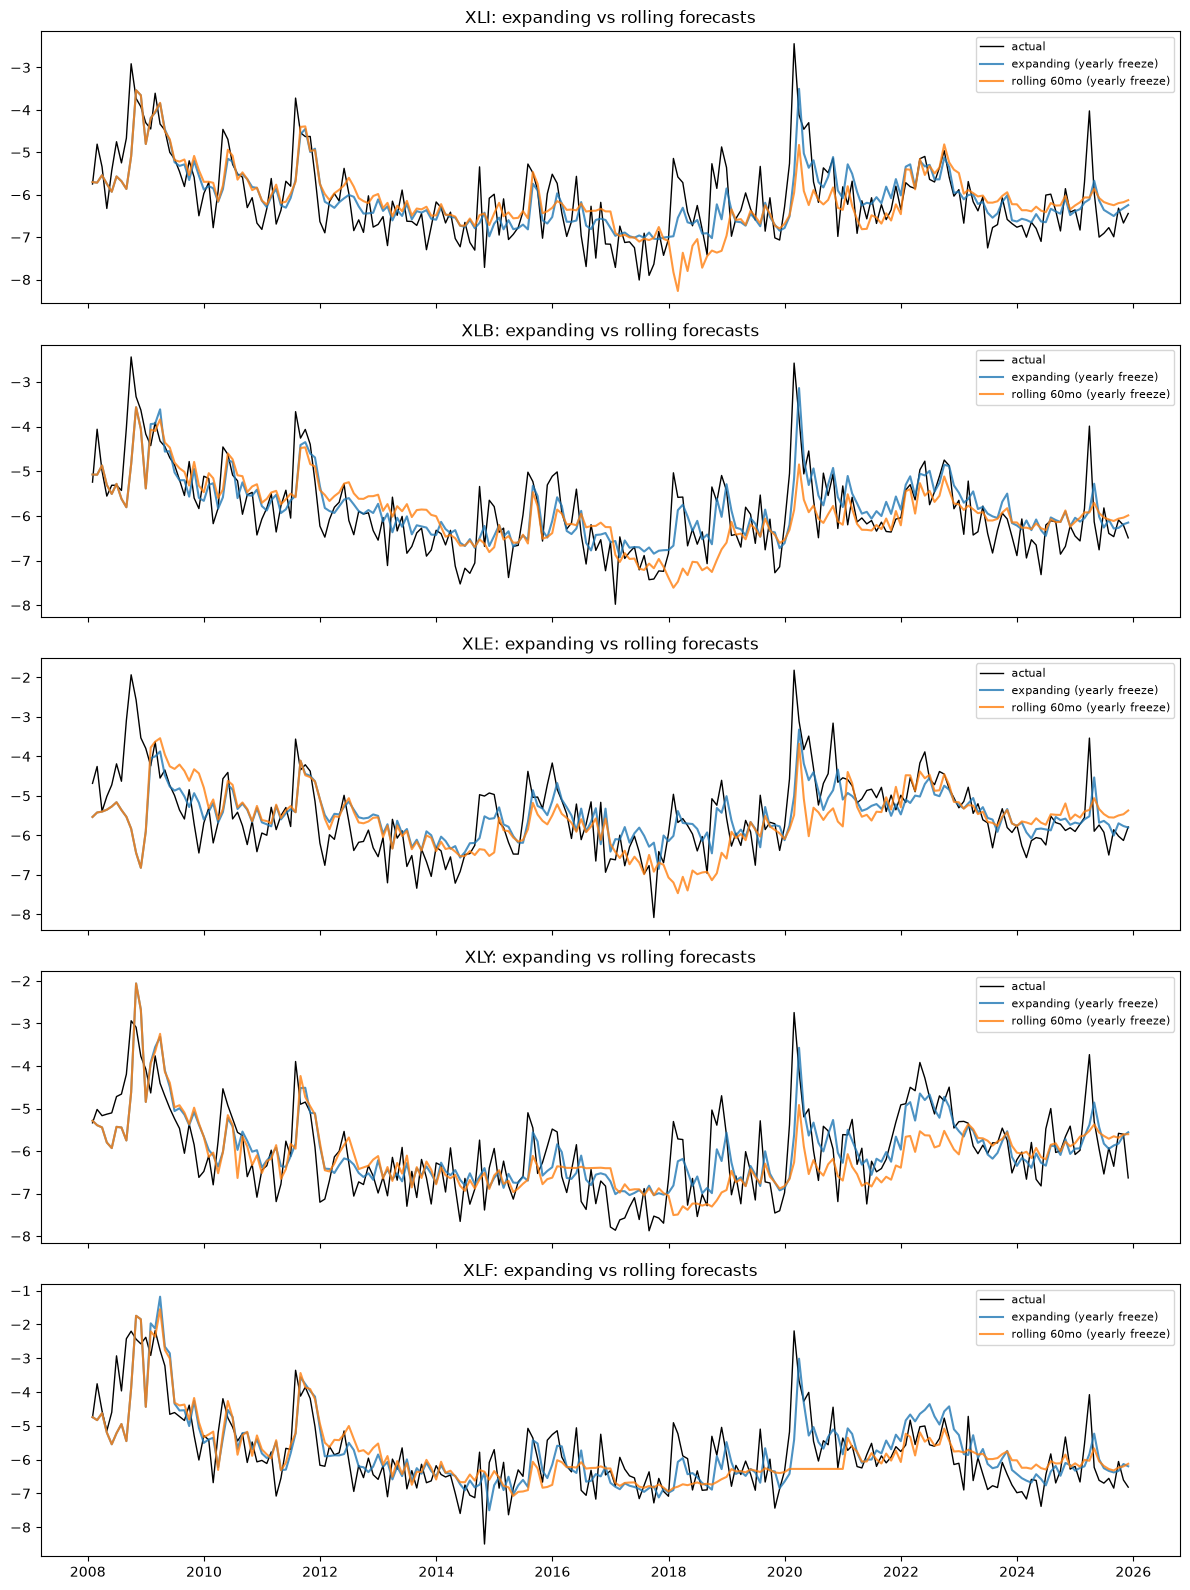

In [18]:
fig, axes = plt.subplots(len(CYCLICAL_TICKERS), 1, figsize=(12, 16), sharex=True)
for ax, ticker in zip(axes, CYCLICAL_TICKERS):
    exp_df = forecasts_expanding[ticker]
    roll_df = forecasts_rolling[ticker]
    ax.plot(exp_df.index, exp_df["log_rv_sq_actual"], label="actual", color="black", linewidth=1)
    ax.plot(exp_df.index, exp_df["log_rv_sq_pred"], label="expanding (yearly freeze)", alpha=0.8)
    ax.plot(roll_df.index, roll_df["log_rv_sq_pred"], label="rolling 60mo (yearly freeze)", alpha=0.8)
    ax.set_title(f"{ticker}: expanding vs rolling forecasts")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()